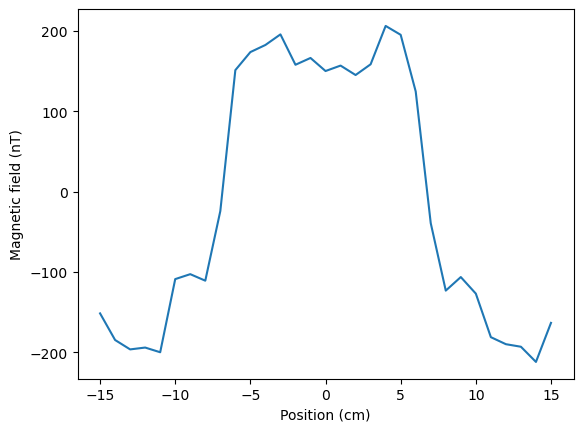

In [2]:
import numpy as np
import matplotlib.pyplot as plt


mu_0 = 1
w_0 = 8     #mean width in no of bands (one band is 0.5 cm)

h = 2       # in cm
filename = 'dataM.txt'

with open(filename, 'r') as file:
    raw_data = file.readlines()

# print(raw_data)
raw_data[0].strip().split(' ')
positions = []
fields = []
for data in raw_data:
    positions.append(float(data.strip().split()[0]))
    fields.append(float(data.strip().split()[1]))
    #print(data.strip().split())
positions = np.array(positions)
fields = np.array(fields)
# for field in fields:
#     print((field))

# Numpy arrat with positions in the first column and the fields in the second
combined = np.block([[positions], [fields]]).T
# print(combined)


plt.plot(combined[:, 0], combined[:, 1])
plt.xlabel('Position (cm)')
plt.ylabel('Magnetic field (nT)')
plt.show()


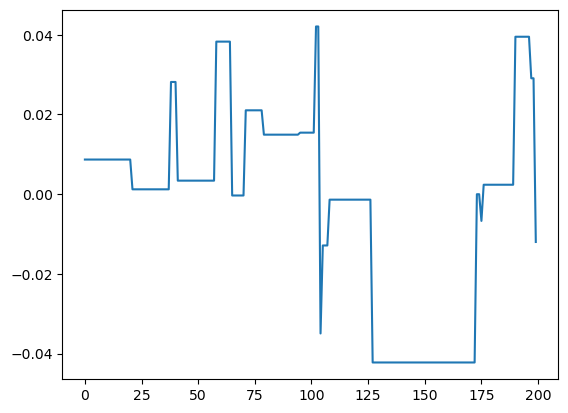

200
[ 8.67400952e-03  8.67400952e-03  8.67400952e-03  8.67400952e-03
  8.67400952e-03  8.67400952e-03  8.67400952e-03  8.67400952e-03
  8.67400952e-03  8.67400952e-03  8.67400952e-03  8.67400952e-03
  8.67400952e-03  8.67400952e-03  8.67400952e-03  8.67400952e-03
  8.67400952e-03  8.67400952e-03  8.67400952e-03  8.67400952e-03
  8.67400952e-03  1.20164707e-03  1.20164707e-03  1.20164707e-03
  1.20164707e-03  1.20164707e-03  1.20164707e-03  1.20164707e-03
  1.20164707e-03  1.20164707e-03  1.20164707e-03  1.20164707e-03
  1.20164707e-03  1.20164707e-03  1.20164707e-03  1.20164707e-03
  1.20164707e-03  1.20164707e-03  2.81405416e-02  2.81405416e-02
  2.81405416e-02  3.37707717e-03  3.37707717e-03  3.37707717e-03
  3.37707717e-03  3.37707717e-03  3.37707717e-03  3.37707717e-03
  3.37707717e-03  3.37707717e-03  3.37707717e-03  3.37707717e-03
  3.37707717e-03  3.37707717e-03  3.37707717e-03  3.37707717e-03
  3.37707717e-03  3.37707717e-03  3.82652851e-02  3.82652851e-02
  3.82652851e-02  3.8

In [3]:
def g(xi, xj):
    g = -mu_0/(2*np.pi)*((xi - xj)**2 - h**2)/((xi - xj)**2 + h**2)**2
    return g

def gen_exp(w0, no_of_stripes=1):
    vec = np.random.exponential(w0 - 1, no_of_stripes)
    if no_of_stripes == 1:
        return int(np.round(vec, 0)[0] + 1)
    else:
        return np.round(vec, 0) + 1
rand_test = gen_exp(w_0, 1)


def gen_bands(w0, length):
    bands = []
    i = 0
    while len(bands) < length:
        stripe_width = gen_exp(w0)
        magn_val = np.random.normal(0, 0.025)
        if len(bands) + stripe_width <= length:
            for j in range(stripe_width):
                bands.append(magn_val)
            i += 1
        else:
            continue
    return np.array(bands)


bands = gen_bands(w_0, 200)
# print(len(bands))


# print(bands)
plt.plot(bands)
plt.show()


print(len(bands))
print(bands)

In [4]:
def stripe_identificator(bands, index):
    indecies = []
    
    i_prev = index
    for i in range(index, len(bands)):         
        if bands[i_prev] == bands[i]:
            indecies.append(i) 
            i_prev = i
        else:
            break
    i_prev = index
    for i in range(index, 0, -1):
        if bands[i_prev] == bands[i]:
            indecies.append(i)
            i_prev = i
        else:
            break
    indecies_sorted = np.sort(np.array(indecies))
    index_low = indecies_sorted[0]
    index_high = indecies_sorted[-1]
    return index_low, index_high

test = np.array([3, 3, 3, 7, 7, 7, 7, 7, 7, 7, 5, 5, 5, 5, 5, 3, 3, 3, 1, 2, 2, 2, 2])
index_low, index_high = stripe_identificator(test, 3)
print(index_low, index_high)

def change_mag(bands):
    val = np.random.normal(0, 0.025)
    bands_length = len(bands)
    random_index = np.random.randint(bands_length)




def add_stripe(bands):
    pass

def remove_stripe(bands):
    pass



3 9


In [5]:
arr = np.array([1, 5, 2, 9, 4, 8, 6, 2, 3, 8, 5, 2, 9, 2])
sorted = np.sort(arr)
print(sorted)

arr2 = np.array([3, 1, 5])
print(np.concatenate((sorted, arr2)))

[1 2 2 2 2 3 4 5 5 6 8 8 9 9]
[1 2 2 2 2 3 4 5 5 6 8 8 9 9 3 1 5]
